# Predicting a synthetic stock from news headlines

Making money in trading is about being fast and smart. Excellent coding covers the "fast" part, but how can we be "smart"?

The goal of Algo is to make **hypotheses** about the world and to be able to **evaluate** them. Whenever we have a hypothesis, the first step is almost always going to be to look at the data.

In this challenge, the market is simulated. Each **session** is one synthetic stock trading for 100 time **bars**. Along the way, news headlines come out. The headlines are fictional and so are the companies they mention.

You see the first half of each session: bars 0 to 49 and the headlines published during them. At the close of bar 49 you take a position, and you hold it for 10 bars, until the close of bar 59. Your job is to predict the stock's return over those 10 bars.

The returns are **market-adjusted**: we subtract the average return across all sessions, so a session's return is positive if it did better than a typical session. Betting that every stock goes up earns nothing here.

## Setup
You should make a copy of this notebook. The first cell will download the data and source needed.

In [1]:
!pip -q install gdown

FOLDER_URL = "https://drive.google.com/drive/folders/1mYOtE9R-XtdcJ4cPVpQYAxiPLD1Dm4vX?usp=sharing"
!gdown --folder "$FOLDER_URL" --output /content

Using cookies from /Users/rgsstudent/.cache/gdown/cookies.txt
Retrieving folder contents
Processing file 1UP6Yr4XYHl9iaqX9BlbuGaVpcp1Os2xo ins_bars.parquet
Processing file 1E_1TrSYdXOEiNxjTRxCOT0XQX65gxmn7 ins_headlines.parquet
Processing file 1yep_-avWzvVxCRIo4CNkjiZyCv7i2p09 ins_returns.parquet
Processing file 1MPaC1U8V2GUZrpAAwB2RpuLdRu2uVcBi oos_bars.parquet
Processing file 1cmNZbk5ILzz_grgFYcxEpj1HToaoIQ2M oos_headlines.parquet
Processing file 1JEVRT8U7eD1XKSzs0PcI1aP3QI9sMJKz sessions.py
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Error:

	[Errno 30] Read-only file system: '/content'

To report issues, please visit https://github.com/wkentaro/gdown/issues.


In [2]:
import sessions # pyright: ignore[reportMissingImports]

# Part 1. Data exploration

The first section of this notebook loads the data and does some basic exploration. You should run each cell. Feel free to add and run additional cells to explore the data further.

## Get the data

You have 10,000 in-sample sessions for training and 10,000 out-of-sample sessions to predict.

Make sure the `ins_*.parquet` and `oos_*.parquet` files are in the same directory as this notebook and `sessions.py`.

In [3]:
df = sessions.get_ins_data()

In [4]:
df.head()

,open,high,low,close,headlines,headline_bars,returns
session,,,,,,,
1000,"[1.0, 0.9965, 0.9964, 0.9918, 0.9878, 0.9932, ...","[1.0002, 0.9978, 0.9976, 0.9929, 0.9934, 0.994...","[0.9963, 0.9948, 0.991, 0.9872, 0.9876, 0.9922...","[0.9967, 0.9964, 0.9916, 0.988, 0.9931, 0.9931...",[Yorval Partners completes planned facility up...,"[6, 12, 15, 24, 31, 41, 48]",-0.007271
1001,"[1.0, 1.0, 0.9963, 0.9963, 0.9992, 1.0003, 0.9...","[1.0021, 1.0002, 0.9964, 0.9997, 1.0009, 1.000...","[0.9995, 0.9958, 0.9943, 0.996, 0.9988, 0.9976...","[1.0001, 0.9961, 0.9958, 0.9994, 1.0, 0.9982, ...",[Plevep Power sees 25% drop in new customer or...,"[0, 4, 8, 10, 12, 18, 19, 22, 24, 27, 32, 34, 44]",-0.002957
1002,"[1.0, 1.0026, 1.0038, 1.0014, 1.0015, 1.0013, ...","[1.0026, 1.0042, 1.0042, 1.0018, 1.003, 1.0018...","[0.9996, 0.9991, 1.0004, 0.9999, 1.0013, 0.998...","[1.0025, 1.0037, 1.0012, 1.0012, 1.0013, 1.000...",[Plevyl Advisors announces $1.2B share buyback...,"[1, 14, 18, 18, 29, 30, 47, 49]",-0.000260
1003,"[1.0, 0.9996, 0.9992, 0.9986, 0.9986, 0.9967, ...","[1.0014, 1.0016, 0.9996, 0.9996, 0.9987, 0.998...","[0.9988, 0.998, 0.9974, 0.9977, 0.9961, 0.9958...","[0.9995, 0.9989, 0.9989, 0.9989, 0.9966, 0.996...",[Plevik Energy sees mixed results in process a...,"[8, 11, 11, 13, 16, 17, 20, 23, 25, 27, 31, 43]",-0.011841
1004,"[1.0, 1.0, 1.0009, 1.0005, 0.9961, 0.999, 1.00...","[1.0009, 1.0033, 1.0016, 1.0006, 1.0001, 1.001...","[0.999, 1.0, 0.9989, 0.9952, 0.9955, 0.999, 1....","[1.0002, 1.0013, 1.0006, 0.9961, 0.999, 1.0006...",[Talvix Holdings secures $250M contract with a...,"[3, 3, 9, 10, 10, 11, 21, 28, 30, 34, 45, 47]",-0.002455


Each row is one in-sample session:

- `open`, `high`, `low`, `close`: arrays of 50 prices, one per bar from 0 to 49. Prices start at 1.
- `headlines`: the headlines published during bars 0 to 49, in order.
- `headline_bars`: the bar each of those headlines was published in.
- `returns`: the market-adjusted return from the close of bar 49 to the close of bar 59. This is what you predict.

## What does a session look like?

In [5]:
session = df.iloc[0]
for bar, headline in zip(session["headline_bars"], session["headlines"], strict=True):
    print(bar, headline)

6 Yorval Partners completes planned facility upgrade in Latin America
12 Yorval Partners secures $500M contract with a major logistics provider
15 Yorval Partners completes planned facility upgrade in Asia Pacific
24 Ilval Financial explores strategic alternatives for supply chain optimization unit
31 Kelvos Resources secures $120M contract with a top-tier research institute
41 Wrelal Financial loses key contract in Scandinavia to competitor
48 Ilval Financial Chief Strategy Officer addresses investor concerns in open letter


Text(0, 0.5, 'Close price')

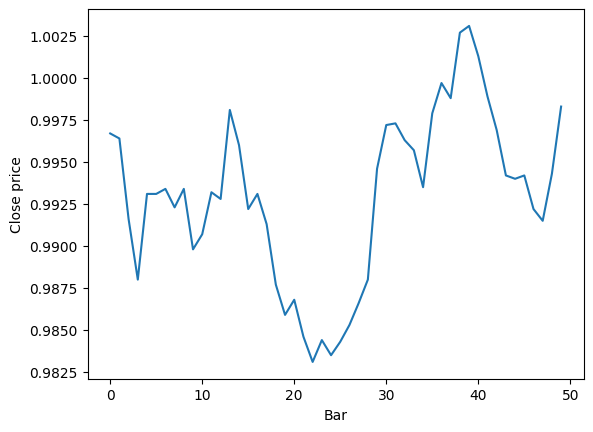

In [9]:
import matplotlib.pyplot as plt

plt.plot(session["close"])
plt.xlabel("Bar")
plt.ylabel("Close price")

## Visualize the distribution of returns

<Axes: >

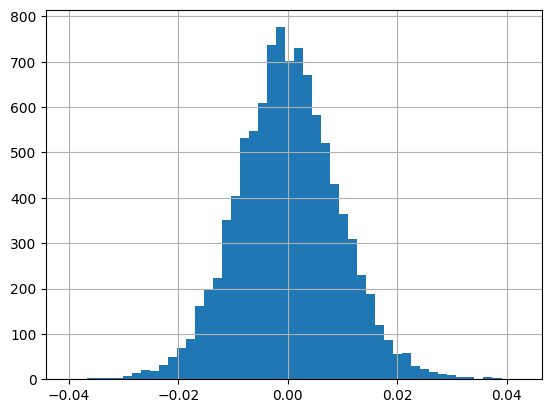

In [10]:
df["returns"].hist(bins=50)

## The whole session, for research

In-sample, you can also see the second half of every session: bars 50 to 99 and their headlines. Out-of-sample you will only have the first half, so your prediction can't use these. They are still useful for research, for example to look at what prices do after a headline.

In [4]:
full_bars = sessions.get_ins_full_bars()
full_headlines = sessions.get_ins_full_headlines()
full_headlines.head()

NameError: name 'sessions' is not defined

# Part 2. Predicting returns

The rest of this notebook is dedicated to the actual task of predicting returns. It explains the task and evaluation, and also gives some basic ideas and useful utility functions.

## Your task

Your goal is to write a function that takes a row of `df` (minus the `returns` column) and returns a prediction of the return from the close of bar 49 to the close of bar 59.
Here is an example of a valid submission, based on the naive idea that "stocks go up".

```python
def my_prediction(row: pd.Series) -> float:
    return 1.0
```

You can call `sessions.get_ins_predictions` to see your predictions on the in-sample dataset: this will be provided as the new column `"pred"` in your dataframe.

In [12]:
def my_prediction(row):
    return 1.0  # stocks go up!

In [13]:
df_predictions = sessions.get_ins_predictions(my_prediction)
df_predictions[["headlines", "returns", "pred"]].head()

  0%|          | 0/10000 [00:00<?, ?it/s]

,headlines,returns,pred
session,,,
1000,[Yorval Partners completes planned facility up...,-0.007271,1.0
1001,[Plevep Power sees 25% drop in new customer or...,-0.002957,1.0
1002,[Plevyl Advisors announces $1.2B share buyback...,-0.000260,1.0
1003,[Plevik Energy sees mixed results in process a...,-0.011841,1.0
1004,[Talvix Holdings secures $250M contract with a...,-0.002455,1.0


## How are you evaluated?

Your goal is to produce a prediction that makes money AS CONSISTENTLY AS POSSIBLE.
We have implemented a very simple trader that will use your prediction to trade. Your score is the *Sharpe ratio* of this trader's performance.

Here is how the trader behaves:
* At the close of bar 49, it takes a position equal to your prediction: it buys if your prediction is positive and sells if it is negative, more for a larger prediction.
* It holds the position until the close of bar 59 and receives `prediction * return`.
* Each session counts as one trading day, so the Sharpe ratio is `sqrt(252) * mean(session_profit) / stddev(session_profit)`. This is a common metric we use in Algo to evaluate our strategies.

## Running an in-sample backtest

We can use your model's in-sample performance to *estimate* how well it will perform out-of-sample. We use these in-sample *backtests* to evaluate our trading hypotheses. The function `sessions.run_ins_backtest` calls your prediction model in-sample and computes the Sharpe ratio (as well as several other metrics).

  0%|          | 0/10000 [00:00<?, ?it/s]

,0
name,my_prediction (in-sample)
sharpe,0.0
total_pnl,0.0
frac_nonzero_predictions,1.0
correlation,0.0
mean_return_positive,0.0
mean_return_negative,NaN
mean_daily_portfolio_size,1.0
annual_return,0.0


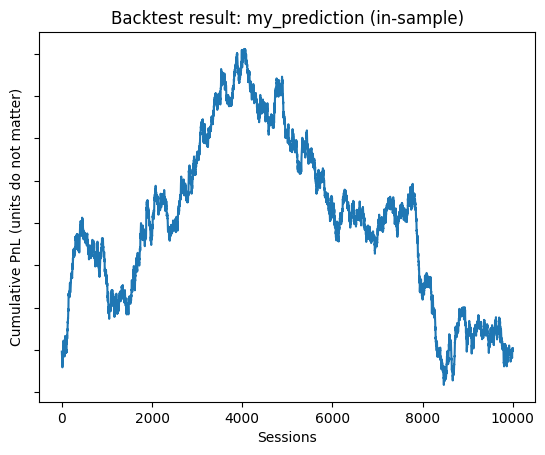

In [14]:
sessions.run_ins_backtest(my_prediction)

Because returns are market-adjusted, "stocks go up" has a Sharpe ratio of about zero. You'll have to do better!

Here's how to read these stats:

- **Sharpe** is the in-sample Sharpe ratio of your prediction model.
- **Total PnL** is the amount of money that your strategy made.
- **Frac nonzero prediction** is the fraction of sessions where your model issued a nonzero prediction.
- **Correlation** is the correlation between your prediction and the returns.
- **Mean return positive** is the average return among sessions for which you issued a positive forecast. Ideally, this number would be positive.
- **Mean return negative** is the average return among sessions for which you issued a negative forecast. Ideally, this number would be negative.
- **Mean daily portfolio size** is the average size of your position. Roughly, it measures the amount of capital you need to actually implement your strategy.
- **Annual return** is the ratio of your total PnL to the total size of your positions. In practice, a strategy that makes a lot of money (total PnL) but has a low annual return is hard to implement due to the large capital requirements.

## Getting ready to go out-of-sample

Once you think you have a good submission, you can run it on the out-of-sample sessions. These are the predictions you will submit!

In [15]:
df_oos_predictions = sessions.get_oos_predictions(my_prediction)
df_oos_predictions.head()

  0%|          | 0/10000 [00:00<?, ?it/s]

,open,high,low,close,headlines,headline_bars,pred
session,,,,,,,
11000,"[1.0, 0.9981, 0.9988, 0.9992, 1.0027, 1.0013, ...","[1.0002, 0.9999, 1.0002, 1.0025, 1.003, 1.0014...","[0.9976, 0.9976, 0.9967, 0.9988, 1.0011, 0.995...","[0.9982, 0.9988, 0.9992, 1.0025, 1.0017, 0.996...",[Krevan Investments faces regulatory review of...,"[1, 7, 9, 20, 27, 30]",1.0
11001,"[1.0, 1.0013, 0.9982, 0.9976, 0.9993, 0.9999, ...","[1.0036, 1.0026, 1.001, 1.002, 1.0006, 1.0035,...","[0.998, 0.9986, 0.9962, 0.9976, 0.9979, 0.9981...","[1.0012, 0.9988, 0.9976, 0.9987, 1.0, 1.0032, ...",[Ulvon Renewables launches next-generation ren...,"[2, 3, 8, 19, 25, 25, 27, 30, 33, 35, 37, 41, 46]",1.0
11002,"[1.0, 0.9985, 1.0002, 0.9928, 0.9896, 0.9889, ...","[1.0012, 1.0009, 1.0003, 0.9941, 0.9899, 0.992...","[0.9982, 0.9981, 0.9919, 0.99, 0.9866, 0.9886,...","[0.9985, 1.0001, 0.9928, 0.99, 0.9887, 0.9916,...",[Kelvik Power wins industry award for excellen...,"[6, 7, 17, 17, 25, 34, 35, 37, 41, 43, 43, 45]",1.0
11003,"[1.0, 0.9968, 0.9968, 0.9987, 0.9965, 0.9938, ...","[1.0003, 0.9979, 0.9983, 1.0006, 0.9966, 0.995...","[0.9966, 0.9948, 0.9948, 0.9969, 0.9926, 0.991...","[0.9971, 0.9973, 0.9983, 0.9969, 0.9936, 0.993...",[Frelis Genomics announces $6.3B share buyback...,"[5, 7, 14, 19, 21, 22, 27, 29, 33, 43, 47]",1.0
11004,"[1.0, 1.0031, 1.0031, 1.006, 1.0096, 1.0094, 1...","[1.0042, 1.0052, 1.0072, 1.0112, 1.0096, 1.012...","[0.9991, 1.0017, 1.0011, 1.0059, 1.0058, 1.009...","[1.003, 1.0039, 1.0061, 1.0095, 1.0089, 1.0111...",[Frelol Software sees 10% drop in new customer...,"[0, 1, 7, 12, 14, 16, 22, 24, 30, 31, 38, 41, ...",1.0


### Scoring

How good is your model? Well, you can't run a backtest, because the out-of-sample returns are secret!

Instead, `sessions.write_submission(...)` writes your out-of-sample predictions to `predictions.csv`. Arcade calls its columns `headline_id,pred`; `headline_id` holds the session number. **Upload that file on the challenge page in arcade**, which scores it against the hidden out-of-sample returns. Your out-of-sample Sharpe appears on the live leaderboard.

Be aware that you only get **10 uploads**, so don't waste them! Use in-sample backtests to decide what is worth submitting.

In [ ]:
# This will not work!
# sessions.run_oos_backtest(my_prediction)

## Ideas to get you started

Here are some ideas you may wish to explore in your submission. Of course, you are not required to pursue these ideas.

**Looking at keywords**. Some headlines sound like good news and some sound like bad news. Maybe a session with more good news does better?

In [ ]:
def keyword_predictor(row):
    score = 0.0
    for headline in row["headlines"]:
        if "secures" in headline:
            score += 1.0
        if "decline" in headline:
            score -= 1.0
    return score

In [ ]:
sessions.run_ins_backtest(keyword_predictor)

In [ ]:
df_oos_predictions = sessions.get_oos_predictions(keyword_predictor)

In [ ]:
sessions.write_submission(
    prediction_df=df_oos_predictions,
    path="predictions.csv",
)
# Now upload predictions.csv on the challenge page in arcade.

In [6]:
import pandas as pd
import sessions

preds = pd.read_csv("predictions.csv").set_index("session")["pred"]

df_ins = sessions.get_ins_data()[["returns"]].join(preds, how="inner")
print(f"{len(df_ins)} of {len(sessions.get_ins_data())} in-sample sessions have predictions")

sessions.PredictionTask.evaluate_predictions(df_ins, label="headline_drift (in-sample)")


KeyError: "None of ['session'] are in the columns"